<a href="https://colab.research.google.com/github/FazelPriyono/Pembelajaran-Mesin-2026/blob/main/TG9_244107020033_FazelPriyono.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1
## Load Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/ML_2026/iris.csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Eksplorasi Data

In [5]:
data.info()
data.describe()
data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


## Visualisasi Data

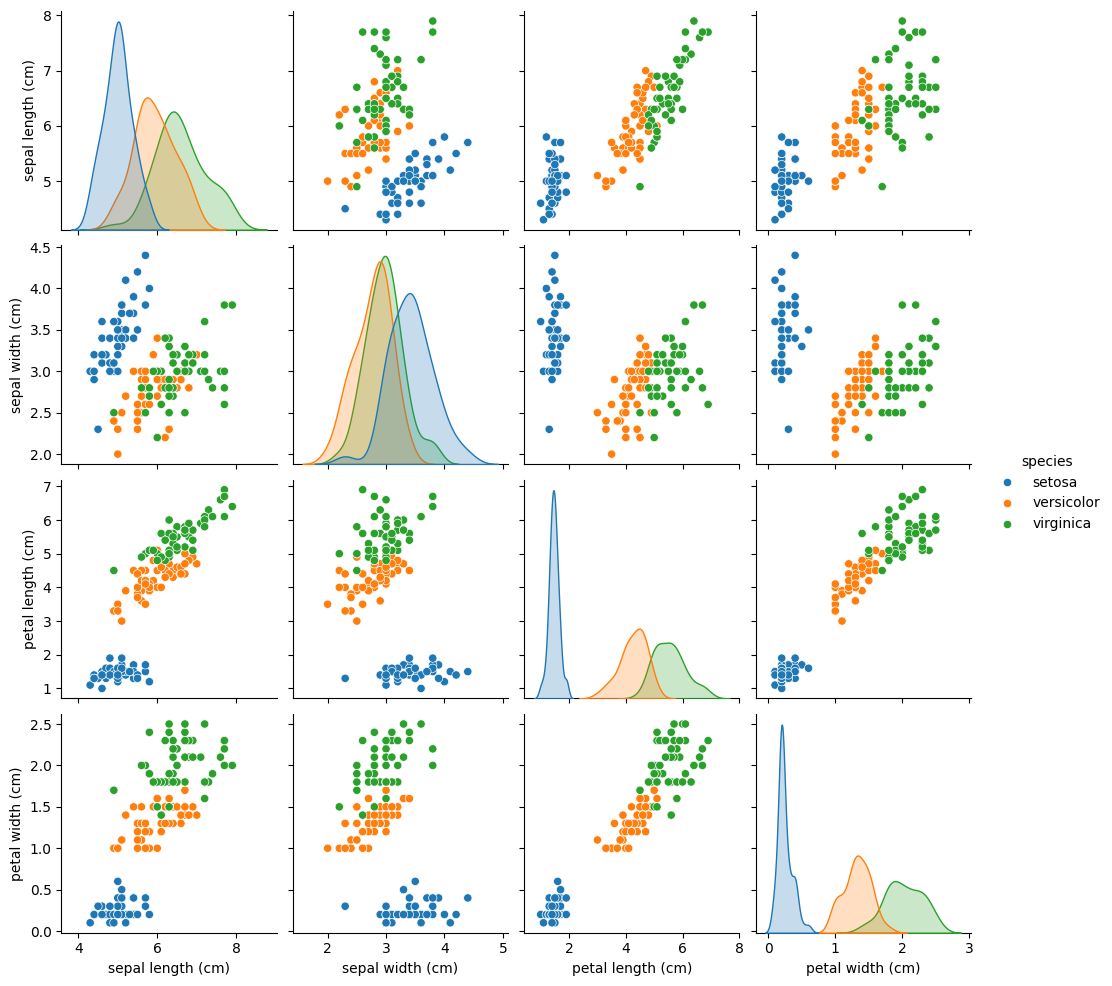

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

## Preprocessing

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Buat Model kNN

In [8]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

## Evaluasi Model kNN

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



## Evaluasi Nilai K

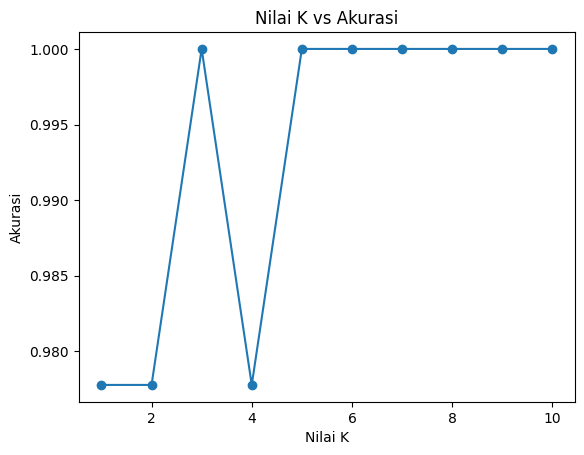

In [10]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

## Perbandingan Akurasi Training dan Testing

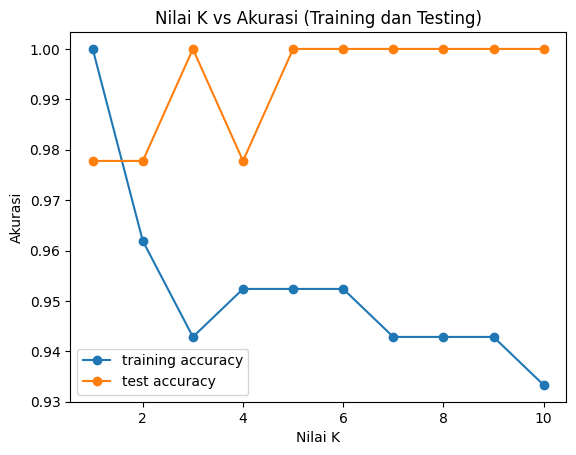

In [11]:
acc_train = []
acc_test = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc_train.append(model.score(X_train, y_train))
    acc_test.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc_train, marker='o', label='training accuracy')
plt.plot(range(1, 11), acc_test, marker='o', label='test accuracy')
plt.title('Nilai K vs Akurasi (Training dan Testing)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.legend()
plt.show()

# Praktikum 2
## Buat Dataset Dummy

In [12]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# Secara defalt, make_classfication menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print(X)
print(y)

[[219 147]
 [190  18]
 [105 191]
 [126 300]
 [195  60]
 [407 145]
 [ 54  83]
 [121 197]
 [ 68 171]
 [ 92  67]
 [ 99  96]
 [ 21 142]
 [110  85]
 [  2  94]
 [112  99]
 [ 79  45]
 [ 84 112]
 [ 36   3]
 [ 59 143]
 [204 133]
 [206 102]
 [ 67 182]
 [ 70  93]
 [ 56  99]
 [129 124]
 [ 65  87]
 [ 46 106]
 [ 86  95]
 [ 89 126]
 [120 107]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


## Membuat Data Frame

In [13]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,219,147,0
1,190,18,0
2,105,191,0
3,126,300,0
4,195,60,0


##  Labeling

In [14]:
# Definisikan nama label
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,219,147,Kelas B
1,190,18,Kelas B
2,105,191,Kelas B
3,126,300,Kelas B
4,195,60,Kelas B


## Visualisasi Data

/tmp/ipykernel_457/2947333296.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_457/2947333296.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


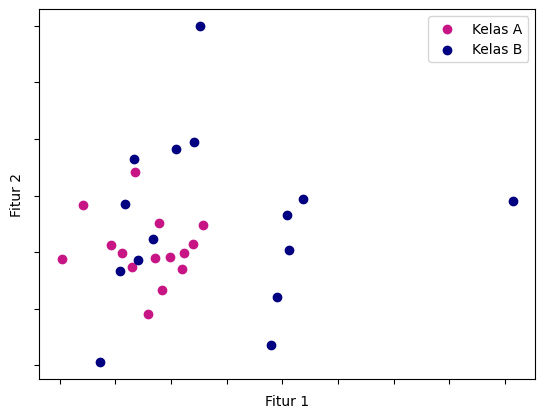

In [15]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

## Model Multinomial Naive Bayes

In [16]:
from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.42857142857142855
Hasil akurasi data test: 0.5555555555555556


## Model Gaussian Naive Bayes

In [17]:
from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.6666666666666666


# Praktikum 3
## Load Data

In [18]:
df = pd.read_csv(
    '/content/drive/MyDrive/ML_2026/spam.csv',
    encoding='latin-1') # spesifikasi encoding diperlukan karena data tidak menggunakan UTF-8

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Preprocessing
### Drop Kolom dan Mengubah Nama Kolom

In [19]:
# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:, 2:], axis=1)

# Ubah nama kolom v1 dan v2
df = df.rename(columns={
    'v1': 'Labels',
    'v2': 'SMS'
})

# Cek data
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Inspeksi Data

In [20]:
# Cek jumlah data per kelas
print(df['Labels'].value_counts())
print('\n')

# Cek kelengkapan data
print(df.info())
print('\n')

# Cek statistik deskriptif
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


### Encoding Label

In [21]:
# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


### Memisahkan Fitur dengan Label

In [22]:
X = df['SMS'].values
y = df['Labels'].values

## Ekstraksi Fitur

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test
# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
X_test = bow.transform(X_test)

In [24]:
# Hasil Ekstraksi Fitur
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


## Training dan Evaluasi Model

In [26]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data training
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data training
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


# TUGAS 1

## Load Data

In [27]:
df = pd.read_csv('/content/drive/MyDrive/ML_2026/voice.csv')

df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


## Inspeksi Data

In [28]:
# Cek ukuran data
print(f'Dimensi data: {df.shape}')
print('\n')

# Cek nama kolom dan tipe data
print(df.info())
print('\n')

# Cek data kosong
print(df.isnull().sum())
print('\n')

# Cek jumlah data per kelas
print(df['label'].value_counts())
print('\n')

# Cek Statistik Deskriptif
display(df.describe().T)

Dimensi data: (3168, 21)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  lab

,count,mean,std,min,25%,50%,75%,max
meanfreq,3168.0,0.180907,0.029918,0.039363,0.163662,0.184838,0.199146,0.251124
sd,3168.0,0.057126,0.016652,0.018363,0.041954,0.059155,0.067020,0.115273
median,3168.0,0.185621,0.036360,0.010975,0.169593,0.190032,0.210618,0.261224
Q25,3168.0,0.140456,0.048680,0.000229,0.111087,0.140286,0.175939,0.247347
Q75,3168.0,0.224765,0.023639,0.042946,0.208747,0.225684,0.243660,0.273469
IQR,3168.0,0.084309,0.042783,0.014558,0.042560,0.094280,0.114175,0.252225
skew,3168.0,3.140168,4.240529,0.141735,1.649569,2.197101,2.931694,34.725453
kurt,3168.0,36.568461,134.928661,2.068455,5.669547,8.318463,13.648905,1309.612887
sp.ent,3168.0,0.895127,0.044980,0.738651,0.861811,0.901767,0.928713,0.981997
sfm,3168.0,0.408216,0.177521,0.036876,0.258041,0.396335,0.533676,0.842936


## Memisahkan Fitur dan Label

In [29]:
# Memisahkan fitur dan label
X = df.drop('label', axis=1)
y = df['label'].map({
    'male': 0,
    'female': 1
})

# Cek dimensi fitur dan label
print(f'Dimensi fitur: {X.shape}')
print(f'Dimensi label: {y.shape}')

# Cek label
print(y.value_counts())

Dimensi fitur: (3168, 20)
Dimensi label: (3168,)
label
0    1584
1    1584
Name: count, dtype: int64


## Membagi Data Training dan Testing

In [30]:
# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


print(f'Dimensi X_train: {X_train.shape}')
print(f'Dimensi X_test: {X_test.shape}')
print(f'Dimensi y_train: {y_train.shape}')
print(f'Dimensi y_test: {y_test.shape}')

Dimensi X_train: (2534, 20)
Dimensi X_test: (634, 20)
Dimensi y_train: (2534,)
Dimensi y_test: (634,)


## Standardisasi Fitur

In [31]:
from sklearn.preprocessing import StandardScaler

# Inisiasi StandardScaler
scaler = StandardScaler()

# Standardisasi data training
X_train_scaled = scaler.fit_transform(X_train)

# Standardisasi data testing
X_test_scaled = scaler.transform(X_test)

## Analisis dan Pemilihan Fitur Terbaik

In [32]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

# Menghitung skor setiap fitur
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train_scaled, y_train)

# Membuat DataFrame skor fitur
fitur_scores = pd.DataFrame({
    'Fitur': X.columns,
    'Skor': selector.scores_
})

# Urutkan fitur berdasarkan skor tertinggi
fitur_scores = fitur_scores.sort_values(
    by='Skor', ascending=False
)

# Tampilkan skor fitur
print(fitur_scores)

       Fitur         Skor
12   meanfun  5816.315917
5        IQR  1567.548219
3        Q25   901.613176
8     sp.ent   814.576514
1         sd   768.720404
9        sfm   377.438366
11  centroid   330.884772
0   meanfreq   330.884772
2     median   233.202792
17    maxdom   111.309620
18   dfrange   107.380153
16    mindom   103.222947
15   meandom    99.111364
10      mode    91.349116
14    maxfun    71.793299
13    minfun    53.252002
7       kurt    16.588127
4        Q75    10.524751
19   modindx     3.295581
6       skew     2.395401


## Membandingkan Jumlah Fitur

In [33]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Urutan fitur berdasarkan skor tertinggi
fitur_urut = fitur_scores['Fitur'].tolist()

# Menyimpan hasil akurasi
hasil_fitur = []

# Menguji jumlah fitur dari 1 sampai seluruh fitur
for k_fitur in range(1, len(fitur_urut) + 1):

    # Memilih fitur
    fitur_pilih = fitur_urut[:k_fitur]

    # Mengambil fitur terpilih
    X_train_pilih = X_train[fitur_pilih]
    X_test_pilih = X_test[fitur_pilih]

    # Standardisasi fitur
    scaler_fitur = StandardScaler()
    X_train_pilih = scaler_fitur.fit_transform(X_train_pilih)
    X_test_pilih = scaler_fitur.transform(X_test_pilih)

    # Membuat dan melatih model kNN
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train_pilih, y_train)

    # Prediksi data testing
    y_pred = knn.predict(X_test_pilih)

    # Menghitung akurasi
    akurasi = accuracy_score(y_test, y_pred)

    hasil_fitur.append({
        'Jumlah Fitur': k_fitur,
        'Akurasi': akurasi,
        'Fitur Digunakan': ', '.join(fitur_pilih)
    })

# Menampilkan hasil
df_hasil_fitur = pd.DataFrame(hasil_fitur)
print(df_hasil_fitur[['Jumlah Fitur', 'Akurasi']])

    Jumlah Fitur   Akurasi
0              1  0.941640
1              2  0.963722
2              3  0.968454
3              4  0.973186
4              5  0.981073
5              6  0.976341
6              7  0.977918
7              8  0.973186
8              9  0.981073
9             10  0.979495
10            11  0.977918
11            12  0.976341
12            13  0.976341
13            14  0.973186
14            15  0.971609
15            16  0.977918
16            17  0.974763
17            18  0.979495
18            19  0.974763
19            20  0.974763


## Grafik Analisis Jumlah Fitur

Jumlah fitur terbaik: 5
Akurasi terbaik: 0.9811
Fitur yang digunakan: meanfun, IQR, Q25, sp.ent, sd


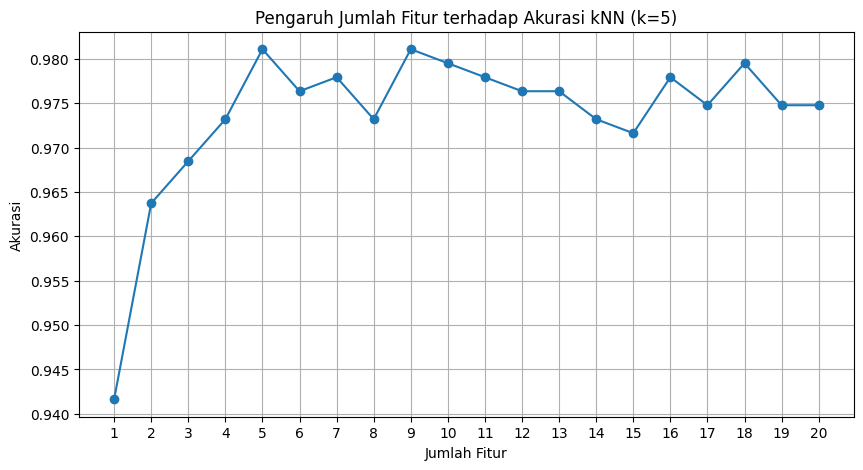

In [34]:
import matplotlib.pyplot as plt

# Menentukan jumlah fitur dengan akurasi tertinggi
idx_terbaik = df_hasil_fitur['Akurasi'].idxmax()
hasil_terbaik = df_hasil_fitur.loc[idx_terbaik]

print(f"Jumlah fitur terbaik: {int(hasil_terbaik['Jumlah Fitur']
if isinstance(hasil_terbaik['Jumlah Fitur'], (int, float))
else len(hasil_terbaik['Fitur Digunakan'].split(', ')))}")
print(f"Akurasi terbaik: {hasil_terbaik['Akurasi']:.4f}")
print(f"Fitur yang digunakan: {hasil_terbaik['Fitur Digunakan']}")

# Membuat grafik jumlah fitur terhadap akurasi
plt.figure(figsize=(10, 5))

plt.plot(
    df_hasil_fitur['Jumlah Fitur'],
    df_hasil_fitur['Akurasi'],
    marker='o'
)

plt.xlabel('Jumlah Fitur')
plt.ylabel('Akurasi')
plt.title('Pengaruh Jumlah Fitur terhadap Akurasi kNN (k=5)')
plt.xticks(range(1, len(fitur_urut) + 1))
plt.grid(True)
plt.show()

## Mencari Nilai k Terbaik

In [35]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Mengambil fitur terbaik dari langkah sebelumnya
fitur_terbaik = hasil_terbaik['Fitur Digunakan'].split(', ')

# Memilih fitur terbaik dari data training dan testing
X_train_terbaik = X_train[fitur_terbaik]
X_test_terbaik = X_test[fitur_terbaik]

# Standardisasi fitur
scaler_terbaik = StandardScaler()

X_train_terbaik = scaler_terbaik.fit_transform(X_train_terbaik)
X_test_terbaik = scaler_terbaik.transform(X_test_terbaik)

# Menyimpan hasil pengujian nilai k
hasil_k = []

# Menguji nilai k dari 1 sampai 31
for nilai_k in range(1, 50, 2):

    # Membuat dan melatih model kNN
    knn = KNeighborsClassifier(n_neighbors=nilai_k)
    knn.fit(X_train_terbaik, y_train)

    # Melakukan prediksi
    y_pred = knn.predict(X_test_terbaik)

    # Menghitung akurasi
    akurasi = accuracy_score(y_test, y_pred)

    hasil_k.append({
        'Nilai k': nilai_k,
        'Akurasi': akurasi
    })

# Menampilkan hasil pengujian
df_hasil_k = pd.DataFrame(hasil_k)
print(df_hasil_k)

    Nilai k   Akurasi
0         1  0.966877
1         3  0.976341
2         5  0.981073
3         7  0.976341
4         9  0.973186
5        11  0.970032
6        13  0.973186
7        15  0.974763
8        17  0.971609
9        19  0.970032
10       21  0.968454
11       23  0.970032
12       25  0.968454
13       27  0.966877
14       29  0.965300
15       31  0.965300
16       33  0.963722
17       35  0.963722
18       37  0.963722
19       39  0.963722
20       41  0.963722
21       43  0.963722
22       45  0.962145
23       47  0.965300
24       49  0.965300


## Grafik Analisis Nilai k Terbaik

Nilai k terbaik: 5.0
Akurasi terbaik: 0.9811


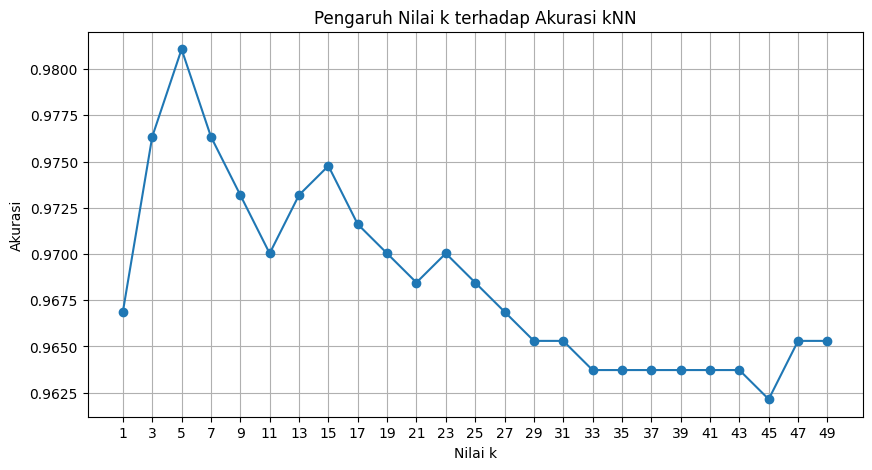

In [36]:
import matplotlib.pyplot as plt

# Menentukan nilai k dengan akurasi tertinggi
idx_k_terbaik = df_hasil_k['Akurasi'].idxmax()
hasil_k_terbaik = df_hasil_k.loc[idx_k_terbaik]

print(f"Nilai k terbaik: {hasil_k_terbaik['Nilai k']}")
print(f"Akurasi terbaik: {hasil_k_terbaik['Akurasi']:.4f}")

# Membuat grafik nilai k terhadap akurasi
plt.figure(figsize=(10, 5))

plt.plot(
    df_hasil_k['Nilai k'],
    df_hasil_k['Akurasi'],
    marker='o'
)
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.title('Pengaruh Nilai k terhadap Akurasi kNN')
plt.xticks(df_hasil_k['Nilai k'])
plt.grid(True)
plt.show()

## Kesimpulan

Berdasarkan eksperimen dan analisis yang telah dilakukan pada **Tugas 1** menggunakan dataset `voice.csv` untuk klasifikasi gender, didapatkan beberapa kesimpulan sebagai berikut:

1. **Fitur Terbaik**:
   * Melalui seleksi fitur menggunakan `SelectKBest` dengan metode ANOVA F-value (`f_classif`), ditemukan bahwa kombinasi **5 fitur terbaik** memberikan performa akurasi tertinggi.
   * Lima fitur tersebut adalah: **`meanfun`**, **`IQR`**, **`Q25`**, **`sp.ent`**, dan **`sd`**.
   * Penggunaan 5 fitur terpilih ini mampu menghasilkan akurasi yang lebih optimal (**98.11%**) dibandingkan dengan menggunakan keseluruhan 20 fitur yang ada di dataset.

2. **Parameter Hyperparameter (Nilai k Teroptimal)**:
   * Berdasarkan pengujian nilai $k$ (jumlah tetangga terdekat) ganjil dari range 1 hingga 49 menggunakan 5 fitur terbaik di atas, didapatkan nilai **$k = 5$** sebagai parameter terbaik.
   * Nilai $k = 5$ tersebut menghasilkan akurasi pengujian tertinggi sebesar **98.11%**. Setelah melewati nilai $k = 5$, akurasi model cenderung menurun secara perlahan seiring bertambahnya nilai $k$.

3. **Kesimpulan Model kNN**:
   * Model k-Nearest Neighbors (kNN) sangat sensitif terhadap pemilihan fitur (*feature selection*) dan penyesuaian skala fitur (*feature scaling*).
   * Dengan memfokuskan model hanya pada fitur-fitur ber-skor tinggi dan menyetel nilai $k$ yang tepat, model dapat bekerja lebih efisien dengan akurasi klasifikasi gender yang sangat tinggi (mencapai ~98.11%).

# TUGAS 2
## Load Dataset

In [37]:
# Membaca dataset
df = pd.read_csv(
    '/content/drive/MyDrive/ML_2026/spam.csv',
    encoding='latin-1'
)

# Menampilkan 5 data pertama
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Preprocesing

In [38]:
# Menghapus kolom yang tidak diperlukan
df = df.drop(df.iloc[:,2:], axis=1)

df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [39]:
# Ubah nama kolom v1 dan v2
df = df.rename(columns={
    'v1': 'Labels',
    'v2': 'SMS'
})

df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [40]:
# Melihat jumlah data setiap kelas
print(df['Labels'].value_counts())

Labels
ham     4825
spam     747
Name: count, dtype: int64


In [41]:
# Melihat informasi dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


In [42]:
# Melihat deskripsi dataset
print(df.describe())

       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


In [43]:
# Data untuk label
new_labels = {
	  'spam': 1,
	  'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)


df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [44]:
# Memisahkan fitur dan label
X = df['SMS']
y = df['Labels']

print(f'Dimensi fitur: {X.shape}')
print(f'Dimensi label: {y.shape}')

Dimensi fitur: (5572,)
Dimensi label: (5572,)


## Membagi Data Training dan Testing

In [45]:
from sklearn.model_selection import train_test_split

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Dimensi X_train: {X_train.shape}')
print(f'Dimensi X_test: {X_test.shape}')
print(f'Dimensi y_train: {y_train.shape}')
print(f'Dimensi y_test: {y_test.shape}')

Dimensi X_train: (4457,)
Dimensi X_test: (1115,)
Dimensi y_train: (4457,)
Dimensi y_test: (1115,)


## Ekstraksi Fitur Menggunakan CountVectorizer

In [46]:
from sklearn.feature_extraction.text import CountVectorizer

# Inisialisasi CountVectorizer dengan stop words
vectorizer = CountVectorizer(stop_words='english')

# Mengubah teks menjadi fitur angka
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Melihat dimensi hasil ekstraksi fitur
print(f'Dimensi X_train_vec: {X_train_vec.shape}')
print(f'Dimensi X_test_vec: {X_test_vec.shape}')

Dimensi X_train_vec: (4457, 7440)
Dimensi X_test_vec: (1115, 7440)


## Membuat dan Melatih Model Multinomial Naive Bayes

In [47]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Multinomial Naive Bayes
mnb = MultinomialNB()

# Melatih model
mnb.fit(X_train_vec, y_train)

# Prediksi data training
y_pred_train = mnb.predict(X_train_vec)

# Prediksi data testing
y_pred_test = mnb.predict(X_test_vec)

## Evaluasi Model CountVectorizer

In [48]:
from sklearn.metrics import accuracy_score

# Menghitung akurasi data training
akurasi_train = accuracy_score(y_train, y_pred_train)

# Menghitung akurasi data testing
akurasi_test = accuracy_score(y_test, y_pred_test)

# Menampilkan hasil akurasi
print(f'Akurasi Training: {akurasi_train:.4f}')
print(f'Akurasi Testing: {akurasi_test:.4f}')

Akurasi Training: 0.9946
Akurasi Testing: 0.9839


## Classification Report dan Confusion Matrix

In [49]:
from sklearn.metrics import classification_report, confusion_matrix

# Menampilkan classification report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Ham', 'Spam']
))

# Menampilkan confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115

Confusion Matrix:
[[960   6]
 [ 12 137]]


## Ekstraksi Fitur Menggunakan TF-IDF

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Inisialisasi TF-IDF dengan stop words
tfidf = TfidfVectorizer(stop_words='english')

# Mengubah teks menjadi fitur angka
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Melihat dimensi hasil ekstraksi fitur
print(f'Dimensi X_train_tfidf: {X_train_tfidf.shape}')
print(f'Dimensi X_test_tfidf: {X_test_tfidf.shape}')

Dimensi X_train_tfidf: (4457, 7440)
Dimensi X_test_tfidf: (1115, 7440)


## Melatih Model Multinomial Naive Bayes dengan TF-IDF

In [51]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model Multinomial Naive Bayes
mnb_tfidf = MultinomialNB()

# Melatih model menggunakan data training
mnb_tfidf.fit(X_train_tfidf, y_train)

# Prediksi data training
y_pred_train_tfidf = mnb_tfidf.predict(X_train_tfidf)

# Prediksi data testing
y_pred_test_tfidf = mnb_tfidf.predict(X_test_tfidf)

## Evaluasi Model TF-IDF

In [52]:
from sklearn.metrics import accuracy_score

# Menghitung akurasi data training
akurasi_train_tfidf = accuracy_score(
    y_train, y_pred_train_tfidf
)

# Menghitung akurasi data testing
akurasi_test_tfidf = accuracy_score(
    y_test, y_pred_test_tfidf
)

# Menampilkan hasil akurasi
print(f'Akurasi Training TF-IDF: {akurasi_train_tfidf:.4f}')
print(f'Akurasi Testing TF-IDF: {akurasi_test_tfidf:.4f}')

Akurasi Training TF-IDF: 0.9845
Akurasi Testing TF-IDF: 0.9686


## Classification Report dan Confusion Matrix TF-IDF

In [53]:
from sklearn.metrics import classification_report, confusion_matrix

# Menampilkan classification report
print("Classification Report TF-IDF:")
print(classification_report(
    y_test,
    y_pred_test_tfidf,
    target_names=['Ham', 'Spam']
))

# Menampilkan confusion matrix
print("Confusion Matrix TF-IDF:")
print(confusion_matrix(y_test, y_pred_test_tfidf))

Classification Report TF-IDF:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115

Confusion Matrix TF-IDF:
[[966   0]
 [ 35 114]]


## Membandingkan CountVectorizer dan TF-IDF

In [54]:
import pandas as pd

# Membuat tabel perbandingan akurasi
hasil_perbandingan = pd.DataFrame({
    'Metode': ['CountVectorizer', 'TF-IDF'],
    'Akurasi Training': [
        akurasi_train,
        akurasi_train_tfidf
    ],
    'Akurasi Testing': [
        akurasi_test,
        akurasi_test_tfidf
    ]
})

# Menampilkan hasil perbandingan
print(hasil_perbandingan)
print('\n')

# Menentukan metode terbaik berdasarkan akurasi testing
if akurasi_test > akurasi_test_tfidf:
    print("Metode terbaik: CountVectorizer")
elif akurasi_test_tfidf > akurasi_test:
    print("Metode terbaik: TF-IDF")
else:
    print("Kedua metode memiliki akurasi testing yang sama")

            Metode  Akurasi Training  Akurasi Testing
0  CountVectorizer          0.994615         0.983857
1           TF-IDF          0.984519         0.968610


Metode terbaik: CountVectorizer


## Kesimpulan

Berdasarkan hasil eksperimen klasifikasi SMS spam menggunakan model **Multinomial Naive Bayes** pada **Tugas 2**, diperoleh kesimpulan sebagai berikut:

1. **Metode Fitur Terbaik**:
   * **CountVectorizer (Bag of Words)** memberikan performa akurasi pengujian (*testing accuracy*) yang lebih baik dibandingkan dengan **TF-IDF Vectorizer**.
   * **Akurasi CountVectorizer**: Training (99.46%), Testing (98.39%)
   * **Akurasi TF-IDF**: Training (98.45%), Testing (96.86%)

2. **Analisis**:
   * Pada kasus klasifikasi spam teks pendek (SMS), kehadiran kata-kata tertentu (*term frequency*) secara mentah/kemunculan langsung yang direpresentasikan oleh `CountVectorizer` cenderung memberikan sinyal klasifikasi yang lebih kuat dan andal bagi model Naive Bayes dibandingkan pembobotan relatif frekuensi dokumen (`TF-IDF`).